In [1]:
# %pip install numpy pandas matplotlib seaborn scikit-learn opencv-python-headless
# %pip install kagglehub
# %pip install pydot
# !apt-get update -qq && apt-get install -y graphviz

In [2]:
import numpy as np
import pandas as pd
import os
import kagglehub
import pathlib
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import tensorflow as tf
from tensorflow.keras.layers import Conv2D, Dense, Dropout
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from pathlib import Path
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, BackupAndRestore
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from tensorflow.keras.models import load_model
import time

2026-10-22 17:06:20.135792: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792688780.155095   12153 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792688780.161202   12153 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792688780.176200   12153 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792688780.176212   12153 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792688780.176214   12153 computation_placer.cc:177] computation placer alr

In [3]:
RAMDOM_STATE = 42
BATCH_SIZE= 16
EPOCHS = 30
image_size = (224, 224)

In [4]:
extensions_valides = (".jpg", ".jpeg", ".png", ".bmp")

labels_par_dossier = {
    "glioma": 0,
    "meningioma": 1,
    "notumor" : 2,
    "pituitary" : 3
}

In [5]:
# Download latest version

dataset_path = Path(
      "/root/.cache/kagglehub/datasets/devana2004/dataset/versions/1/Data"
)

if dataset_path.exists() and any(dataset_path.iterdir()):
      print("✅ Dataset déjà présent dans le cache.")
      print("Chemin :", dataset_path)
      print("Contenu :", [p.name for p in dataset_path.iterdir()])
else:
      print("❌ Dataset absent ou dossier vide.")
      dataset_path = kagglehub.dataset_download("devana2004/dataset")
      dataset_path = dataset_path +'/Data'


print("Path to dataset files:", dataset_path)

Path("fine_tuning").mkdir(parents=True, exist_ok=True)


✅ Dataset déjà présent dans le cache.
Chemin : /root/.cache/kagglehub/datasets/devana2004/dataset/versions/1/Data
Contenu : ['glioma', 'meningioma', 'notumor', 'pituitary']
Path to dataset files: /root/.cache/kagglehub/datasets/devana2004/dataset/versions/1/Data


In [6]:

def check_data(path, extensions_valides, labels_par_dossier):
    num_skiped = 0
    num_corrompu = 0
    images= []
    labels = []
    try:
        data_dir = pathlib.Path(path)
        for folder in data_dir.iterdir():
            if folder.is_dir():
                for file in folder.iterdir():
                    if folder.name in labels_par_dossier.keys():
                        if not file.is_file():
                            continue

                        if file.is_file() and not file.name.lower().endswith(extensions_valides):
                            num_skiped +=1
                            continue

                        else:
                            image = cv2.imread(str(file))

                            if image is None:
                                num_corrompu +=1
                                continue
                            
                            else:
                                image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
                                images.append(image)
                                label = labels_par_dossier[folder.name]
                                labels.append(label)

        print('nombre de fichiers invlaid', num_skiped)
        print('nombre de fichiers corrompus', num_corrompu)
    except (FileNotFoundError):
        print("Erreur : Le fichier n'existe pas.")
    except Exception as e:
        # Capture toute autre erreur inattendue
        print(f"Erreur inattendue : {e}")
    return images, labels

images, labels = check_data(dataset_path, extensions_valides,  labels_par_dossier)

nombre de fichiers invlaid 0
nombre de fichiers corrompus 0


In [7]:
def preparing_data(image_size):
    images_resized =[]
    for image in images:
        resized = cv2.resize(image, image_size, interpolation=cv2.INTER_LINEAR)
        images_resized.append(resized)
    
    images_array_2d = np.array(images_resized)
    
    labeles_array_2d = np.array(labels)
    
    return images_array_2d, labeles_array_2d

images_array_2d, labeles_array_2d = preparing_data(image_size)
print(images_array_2d.shape, labeles_array_2d.shape)

(7023, 224, 224, 3) (7023,)


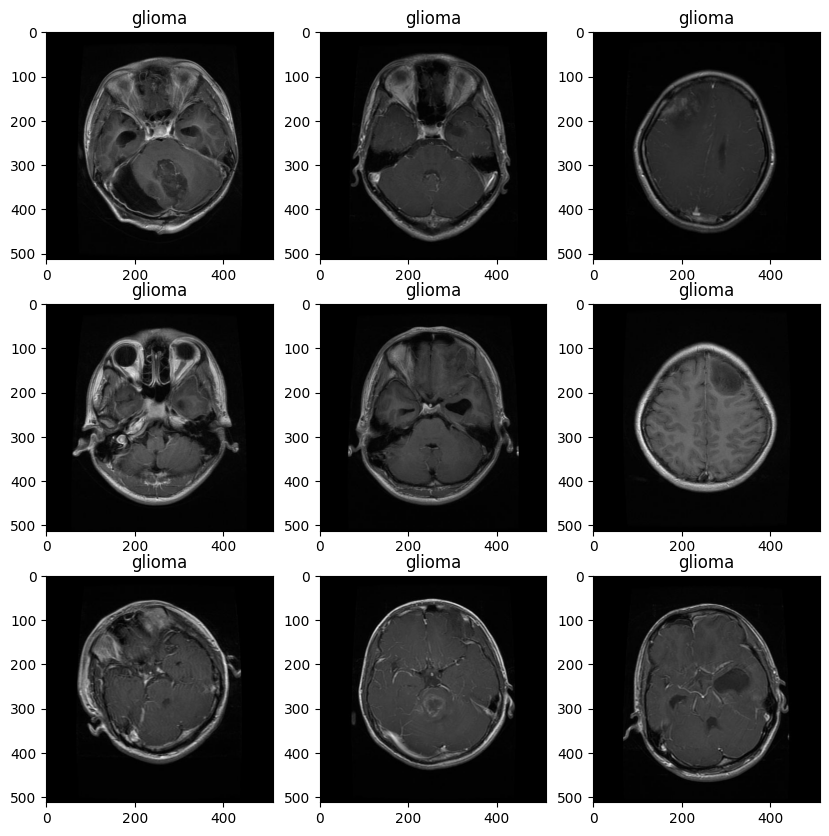

glioma : 1621 images
meningioma : 1645 images
notumor : 2000 images
pituitary : 1757 images


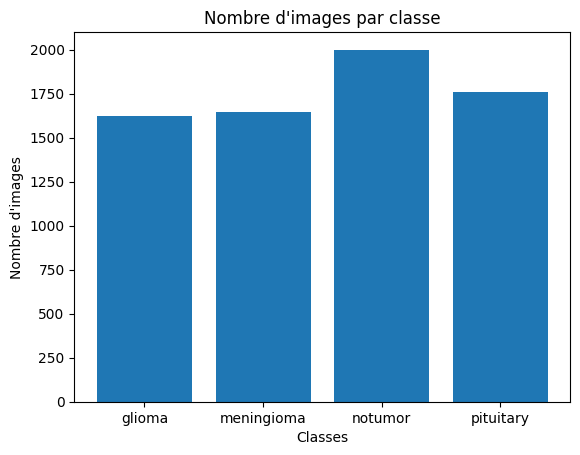

<Figure size 640x480 with 0 Axes>

In [8]:
plt.figure(figsize=(10,10))
n_images = min(9, len(images))

for i in range(n_images):
    ax = plt.subplot(3,3,i+1)
    image_rgb = cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB)
    plt.imshow(image_rgb)
    nom_class = next((k for k, v in labels_par_dossier.items() if v == labels[i]), None)
    plt.title(nom_class)
plt.show()
plt.savefig('fine_tuning/example1.png')

effectifs = Counter(labels)

noms_classes = list(labels_par_dossier.keys())
nombres_images = [
    effectifs[labels_par_dossier[nom]]
    for nom in noms_classes
]

for nom, nombre in zip(noms_classes, nombres_images):
    print(f'{nom} : {nombre} images')

plt.bar(noms_classes, nombres_images)
plt.title("Nombre d'images par classe")
plt.xlabel('Classes')
plt.ylabel("Nombre d'images")
plt.show()
plt.savefig('fine_tuning/image_par_class.png')

In [10]:
def spliting_data(X, y):
    X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RAMDOM_STATE)
    X_test, X_val, y_test, y_val = train_test_split(X_tmp, y_tmp, test_size=0.5,  stratify=y_tmp, random_state=RAMDOM_STATE)
    print(X_train.shape, X_test.shape, X_val.shape)
    print(y_train.shape, y_test.shape, y_val.shape)

    return  X_train, X_test, X_val, y_train, y_test, y_val
    
X_train, X_test, X_val, y_train, y_test, y_val = spliting_data(images_array_2d, labeles_array_2d)


def  normalisation(X, seuil):
    return X.astype('float32') / seuil

def preprocess(image,label):
    # image = resize(image,image_size)
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image) #scale [-1,1]
    return image, label
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

def prep(X, y, training=True):
    # X = normalisation(X, 255.0)
    with tf.device("/CPU:0"):

        X_ds = tf.data.Dataset.from_tensor_slices((X, y))
        X_ds = X_ds.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
        
    if training:
        X_ds = X_ds.shuffle(buffer_size=X_ds.cardinality())
        
    X_ds = X_ds.batch(batch_size=BATCH_SIZE)
    return X_ds.prefetch(buffer_size=tf.data.AUTOTUNE)

Train_ds =  prep(X_train, y_train, training=True)
Test_ds = prep(X_test, y_test, training=False)
Val_ds = prep(X_val, y_val, training=False)
print(Train_ds, Test_ds, Val_ds)

(5618, 224, 224, 3) (702, 224, 224, 3) (703, 224, 224, 3)
(5618,) (702,) (703,)
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))> <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))> <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>


In [11]:
for image_batch, label_batch in Train_ds:
    print(image_batch.shape)
    print(label_batch.shape)
    break

(16, 224, 224, 3)
(16,)


In [12]:
for images, labels in Train_ds.take(1):
      print("Forme des images :", images.shape)
      print("Valeur minimale :", float(tf.reduce_min(images)))
      print("Valeur maximale :", float(tf.reduce_max(images)))
      print("Labels :", labels[:10].numpy())

Forme des images : (16, 224, 224, 3)
Valeur minimale : -1.0
Valeur maximale : 1.0
Labels : [0 3 0 2 3 2 2 3 2 1]


2026-10-22 17:07:14.468073: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [13]:
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(
        height_factor=(-0.2, 0.2),
        width_factor=(-0.2, 0.2)
    ),
    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    ),
    layers.RandomZoom(0.1)
], name="data_augmentation")

2026-10-22 17:07:20.508975: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


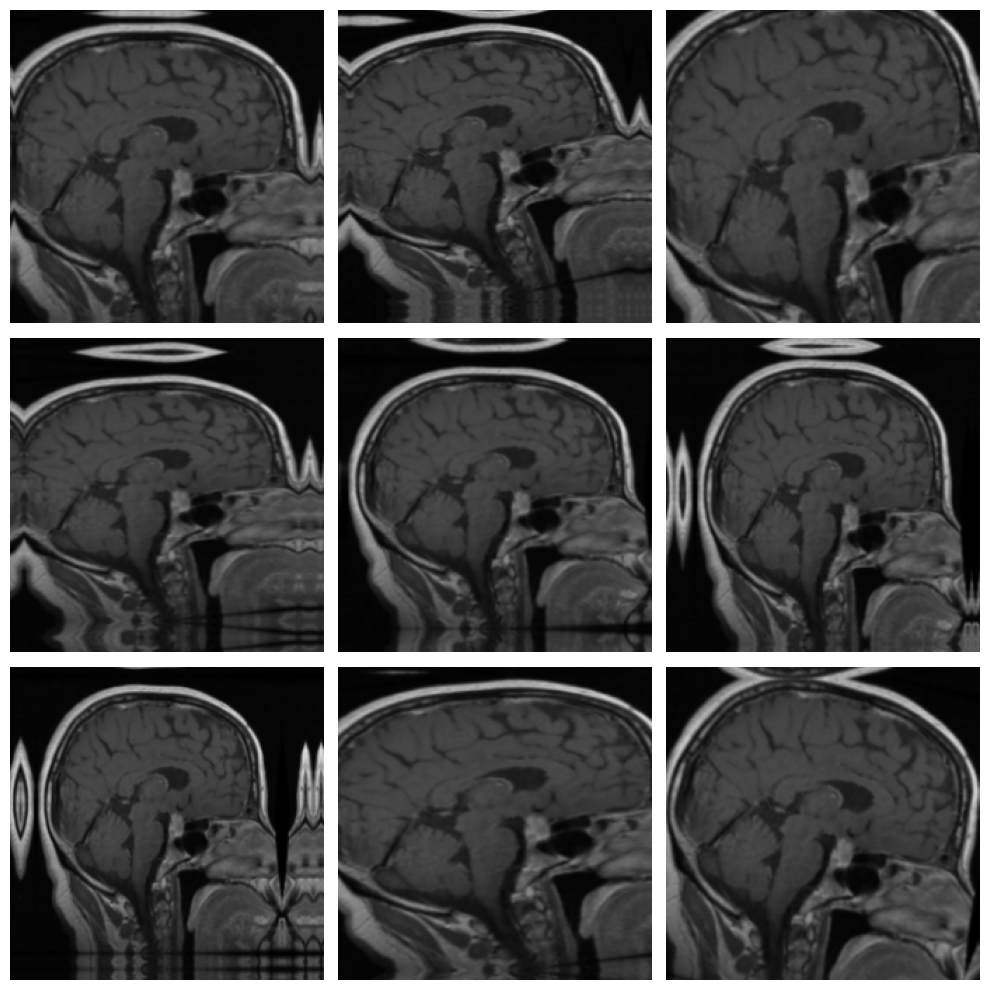

In [14]:
# for image, _ in Train_ds.take(1):
#       plt.figure(figsize=(10,10))
#       first_image = image[0]
#       for i in range(9):
#             ax = plt.subplot(3, 3, i+1)
#             augmented_image = data_augmentation(tf.expand_dims(first_image, 0))
#             plt.imshow(augmented_image[0])
#             plt.axis('off')
#             plt.savefig('fine_tuning/image_apres_data_augmentation.png')


for images, labels in Train_ds.take(1):
      first_image = images[0]

      plt.figure(figsize=(10, 10))

      for i in range(9):
            ax = plt.subplot(3, 3, i + 1)

            # Appliquer une transformation à la même image
            augmented_image = data_augmentation(
                  tf.expand_dims(first_image, axis=0),
                  training=True
            )

            # Reconvertir les pixels de [-1, 1] vers [0, 1]
            image_to_display = (augmented_image[0] + 1.0) / 2.0
            image_to_display = tf.clip_by_value(
                  image_to_display, 0.0, 1.0
            )

            plt.imshow(image_to_display.numpy())
            plt.axis("off")

      plt.tight_layout()
      plt.savefig(
            "fine_tuning/image_apres_data_augmentation.png"
      )
plt.show()


In [ ]:
# preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

In [15]:
IMG_SHAPE = image_size + (3,)
base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SHAPE, include_top=False, weights='imagenet')

In [16]:
image_batch, label_batch = next(iter(Train_ds))
feature_batch = base_model(image_batch)
print(feature_batch.shape)

I0000 00:00:1792688862.807957   12153 cuda_dnn.cc:529] Loaded cuDNN version 90300


(16, 7, 7, 1280)


In [17]:
base_model.trainable = False

In [18]:
base_model.summary()

Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [19]:
global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
feature_batch_average = global_average_layer(feature_batch)
print(feature_batch_average.shape)

(16, 1280)


In [20]:
prediction_layer = tf.keras.layers.Dense(4, activation="softmax")
prediction_batch = prediction_layer(feature_batch_average)
print(prediction_batch.shape)

(16, 4)


In [21]:
inputs = tf.keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x  = global_average_layer(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = prediction_layer(x)
model = tf.keras.Model(inputs, outputs)

In [22]:
base_learing_rate = 0.0001

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=base_learing_rate),
            loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
      metrics=['accuracy'])

In [23]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [24]:
len(model.trainable_variables)

2

In [25]:
loss0, accuracy0 = model.evaluate(Val_ds)
print('initial loss {:.2f}'.format(loss0))
print('initial accuracy {:.2f}'.format(accuracy0))

/venv/main/lib/python3.10/site-packages/keras/src/backend/tensorflow/nn.py:708: UserWarning: "`sparse_categorical_crossentropy` received `from_logits=True`, but the `output` argument was produced by a Softmax activation and thus does not represent logits. Was this intended?
  output, from_logits = _get_logits(


44/44 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.2108 - loss: 1.7166
initial loss 1.69
initial accuracy 0.23


Fine-Tuning

In [26]:
base_model.trainable = True
base_model.trainable = True
for layer in base_model.layers[:-20]:
      layer.trainable = False

In [27]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
            loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
      metrics=['accuracy'])

In [28]:
# Path("models").mkdir(parents=True, exist_ok=True)
# Path("backup").mkdir(parents=True, exist_ok=True)

output_dir = Path("/fine_tuning/models")
backup_dir = Path("/fine_tuning/backup")

output_dir.mkdir(parents=True, exist_ok=True)
backup_dir.mkdir(parents=True, exist_ok=True)

In [29]:
# checkpoint = ModelCheckpoint(
#     filepath=str(output_dir / "model_epoch_{epoch:03d}.keras"),
#     monitor="val_accuracy",
#     save_best_only=False,
#     save_weights_only=False,
#     save_freq="epoch",
#     verbose=1
# )
checkpoint_best = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(output_dir / "best_model.keras"),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)
callback = EarlyStopping(monitor='val_loss',patience=4, restore_best_weights=True)
backup = BackupAndRestore(
    '/fine_tuning/backup/', save_freq="epoch", double_checkpoint=True, delete_checkpoint=False
)

In [31]:
debut = time.time()

history = model.fit(Train_ds, epochs=EPOCHS,
                  validation_data=(Val_ds),  callbacks=[callback, backup, checkpoint_best])

fin = time.time()

duree = fin - debut

print(f"Durée de l'entraînement : {duree:.2f} secondes")
print(f"Durée en minutes : {duree / 60:.2f} minutes")

Epoch 1/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.4959 - loss: 1.1352
Epoch 1: val_loss improved from inf to 1.43870, saving model to /fine_tuning/models/best_model.keras
352/352 ━━━━━━━━━━━━━━━━━━━━ 30s 61ms/step - accuracy: 0.4961 - loss: 1.1349 - val_accuracy: 0.2987 - val_loss: 1.4387
Epoch 2/30
351/352 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.6333 - loss: 0.8878
Epoch 2: val_loss did not improve from 1.43870
352/352 ━━━━━━━━━━━━━━━━━━━━ 19s 52ms/step - accuracy: 0.6334 - loss: 0.8877 - val_accuracy: 0.5121 - val_loss: 1.4430
Epoch 3/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.6783 - loss: 0.8048
Epoch 3: val_loss improved from 1.43870 to 1.42126, saving model to /fine_tuning/models/best_model.keras
352/352 ━━━━━━━━━━━━━━━━━━━━ 19s 53ms/step - accuracy: 0.6783 - loss: 0.8047 - val_accuracy: 0.4339 - val_loss: 1.4213
Epoch 4/30
351/352 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.6975 - loss: 0.7672
Epoch 4: val_loss improved from 1.42126 to

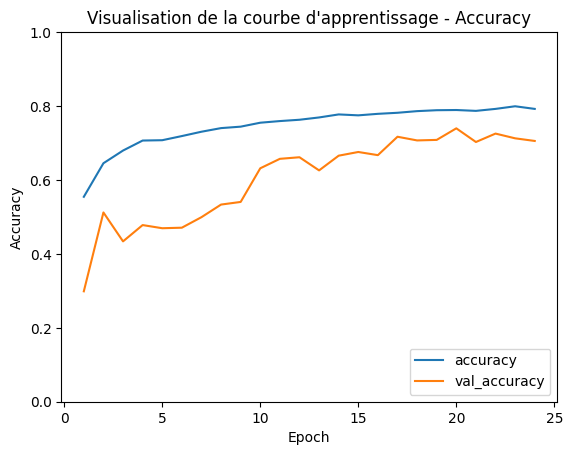

In [32]:
epochs = range(1, len(history.history['val_accuracy']) + 1)
plt.plot(epochs, history.history['accuracy'], label='accuracy')
plt.plot(epochs, history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')
plt.title("Visualisation de la courbe d'apprentissage - Accuracy")
plt.savefig("/fine_tuning/accuracy_visualisation.png")

44/44 - 1s - 29ms/step - accuracy: 0.7692 - loss: 0.6332


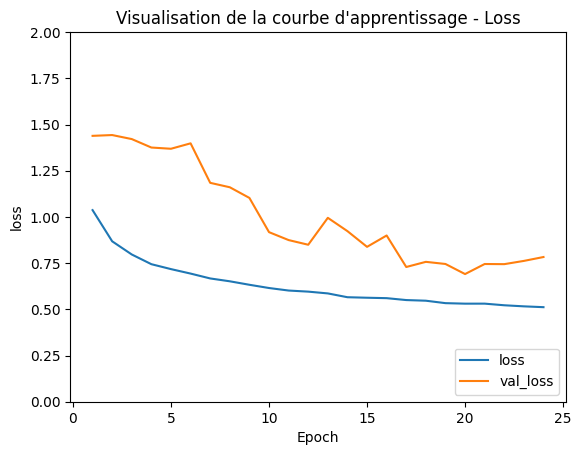

In [33]:

plt.plot(epochs, history.history['loss'], label='loss')
plt.plot(epochs, history.history['val_loss'], label = 'val_loss')
plt.xlabel('Epoch')
plt.ylabel('loss')
plt.ylim([0, 2])
plt.title("Visualisation de la courbe d'apprentissage - Loss")
plt.legend(loc='lower right')
plt.savefig("/fine_tuning/loss_visualisation.png")
test_loss, test_acc = model.evaluate(Test_ds, verbose=2)

In [34]:
Y = model.predict(Test_ds)
y_pred=np.argmax(Y, axis=1)
y_pred

44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step


array([1, 0, 2, 3, 3, 2, 1, 3, 3, 1, 1, 0, 2, 3, 3, 2, 2, 1, 1, 2, 3, 3,
       2, 0, 3, 0, 2, 2, 2, 0, 2, 2, 2, 0, 1, 3, 3, 1, 2, 2, 2, 2, 1, 3,
       3, 3, 2, 1, 3, 0, 2, 3, 3, 3, 2, 2, 1, 2, 2, 0, 0, 2, 3, 2, 3, 2,
       2, 0, 2, 2, 2, 3, 1, 0, 3, 3, 3, 0, 2, 2, 3, 0, 0, 3, 3, 2, 3, 3,
       2, 1, 2, 2, 0, 1, 2, 2, 2, 0, 2, 2, 3, 3, 3, 2, 0, 1, 0, 1, 2, 3,
       2, 2, 3, 0, 2, 3, 2, 0, 0, 0, 2, 3, 3, 3, 2, 2, 0, 0, 3, 2, 0, 2,
       3, 3, 0, 0, 2, 3, 2, 2, 2, 3, 3, 3, 2, 2, 1, 1, 2, 3, 3, 0, 2, 2,
       2, 2, 2, 3, 1, 0, 2, 3, 3, 2, 0, 3, 2, 0, 3, 3, 3, 1, 1, 0, 2, 0,
       3, 0, 3, 3, 2, 2, 2, 0, 3, 1, 2, 2, 2, 3, 3, 3, 0, 0, 3, 2, 3, 3,
       2, 2, 0, 0, 0, 3, 0, 2, 3, 2, 1, 3, 0, 3, 2, 3, 2, 0, 2, 2, 0, 2,
       0, 2, 0, 0, 0, 3, 2, 1, 3, 2, 3, 0, 2, 0, 0, 3, 3, 0, 1, 2, 2, 2,
       3, 1, 0, 2, 2, 3, 0, 2, 3, 2, 2, 0, 3, 2, 2, 3, 1, 2, 2, 3, 3, 3,
       2, 2, 2, 3, 3, 3, 2, 1, 2, 3, 2, 1, 2, 2, 3, 0, 2, 2, 2, 3, 0, 1,
       2, 0, 3, 1, 2, 3, 0, 3, 0, 2, 0, 2, 2, 0, 0,

In [35]:
y_true = np.concatenate([
    labels.numpy() for  images, labels in Test_ds
])
y_true

array([3, 0, 2, 3, 3, 0, 1, 3, 3, 1, 0, 0, 2, 0, 3, 2, 0, 1, 1, 2, 3, 3,
       3, 0, 1, 3, 3, 1, 2, 0, 3, 2, 2, 0, 1, 3, 3, 1, 1, 1, 2, 2, 1, 1,
       3, 1, 2, 0, 1, 0, 2, 3, 3, 3, 2, 2, 1, 2, 1, 0, 0, 1, 3, 1, 3, 2,
       2, 0, 2, 2, 2, 3, 1, 0, 1, 3, 3, 1, 2, 2, 3, 1, 0, 3, 3, 2, 1, 3,
       2, 1, 0, 2, 0, 1, 2, 3, 2, 0, 2, 2, 3, 0, 3, 2, 0, 1, 0, 0, 2, 3,
       2, 2, 1, 0, 2, 1, 0, 0, 0, 0, 2, 3, 0, 3, 1, 1, 0, 0, 3, 2, 0, 2,
       3, 1, 0, 0, 2, 2, 2, 2, 2, 3, 3, 3, 3, 0, 1, 1, 2, 3, 3, 0, 2, 3,
       2, 2, 2, 1, 0, 0, 1, 3, 3, 1, 0, 3, 2, 0, 1, 3, 3, 1, 1, 1, 3, 1,
       1, 0, 0, 3, 2, 2, 2, 0, 3, 1, 2, 2, 2, 3, 3, 3, 1, 0, 3, 2, 1, 3,
       2, 1, 0, 0, 0, 3, 0, 2, 3, 2, 1, 3, 0, 1, 1, 1, 2, 0, 2, 2, 1, 2,
       2, 3, 0, 1, 0, 3, 1, 1, 1, 2, 3, 0, 2, 0, 0, 3, 3, 0, 0, 2, 1, 2,
       3, 1, 0, 1, 2, 3, 0, 1, 3, 2, 2, 0, 3, 2, 2, 1, 1, 2, 2, 3, 3, 1,
       1, 0, 2, 3, 3, 3, 0, 1, 2, 1, 0, 1, 1, 1, 3, 0, 2, 2, 1, 0, 0, 1,
       2, 0, 3, 1, 2, 3, 0, 1, 1, 2, 0, 2, 2, 0, 0,

Sur les 164 images de meningioma, seulement 86 sont correctement identifiées. 57 sont classées comme pituitary, soit environ 35 % de cette classe.
Le modèle semble donc avoir tendance à privilégier la classe pituitary lorsqu'il hésite sur certaines images.

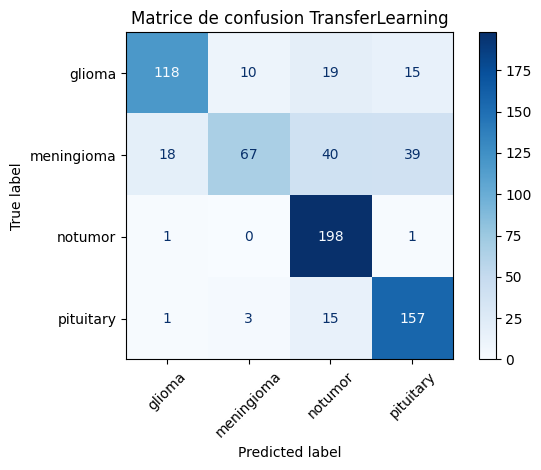

<Figure size 640x480 with 0 Axes>

In [36]:
cm = confusion_matrix(y_true, y_pred)

# effectifs = Counter(labels)
tensor_set = {labels.ref()}
tensor_set
noms_classes = list(labels_par_dossier.keys())

cms = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=noms_classes)
cms.plot(cmap='Blues', xticks_rotation=45)
plt.title("Matrice de confusion TransferLearning")
plt.tight_layout()
plt.show()
plt.savefig("/fine_tuning/matrice_confusion.png")

In [37]:
print(classification_report(y_true, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.86      0.73      0.79       162
           1       0.84      0.41      0.55       164
           2       0.73      0.99      0.84       200
           3       0.74      0.89      0.81       176

    accuracy                           0.77       702
   macro avg       0.79      0.75      0.75       702
weighted avg       0.79      0.77      0.75       702



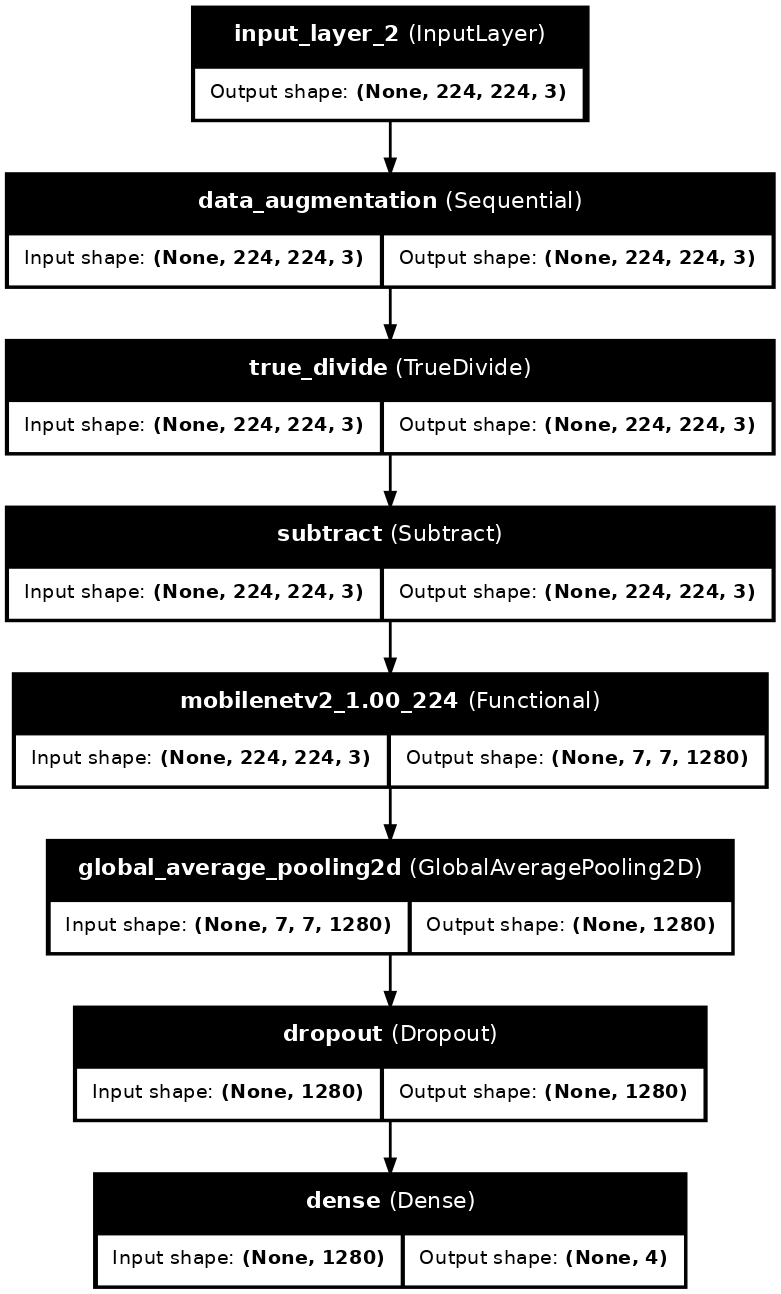

In [38]:

from IPython.display import Image, display
out_dir = Path("/fine_tuning/tmp")
out_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path1 = output_dir / "architecture_model_fine_tuning.png"
tf.keras.utils.plot_model(model, to_file=str(checkpoint_path1), show_shapes=True,show_layer_names=True,
dpi=100
)

# display(Image(filename=checkpoint_path1))

2026-10-22 14:29:08.690980: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


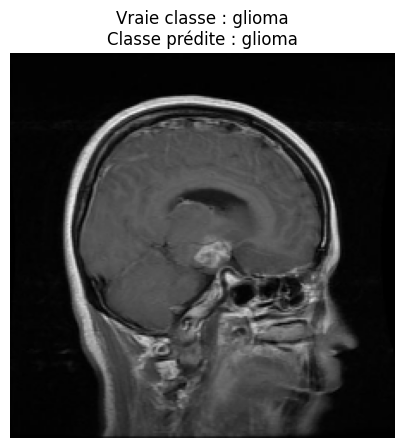

<Figure size 640x480 with 0 Axes>

In [ ]:
i = 5

# Récupérer les images du dataset dans le même ordre
images_all = np.concatenate([
    images.numpy() for images, labels in Test_ds
])

class_names = ['glioma', 'meningioma', 'notumor', 'pituitary']

# Afficher l'image exacte
plt.figure(figsize=(5, 5))
plt.imshow(images_all[i])
plt.title(
    f"Vraie classe : {class_names[int(y_true[i])]}\n"
    f"Classe prédite : {class_names[int(y_pred[i])]}"
)
plt.axis("off")
plt.show()
plt.savefig("/fine_tuning/tru_predict_image.png")


In [39]:
best_model = load_model(output_dir / "best_model.keras")
best_model.summary()
test_loss, test_accuracy = best_model.evaluate(Test_ds)

print("Test accuracy :", test_accuracy)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,685,518 (17.87 MB)

 Trainable params: 1,211,204 (4.62 MB)

 Non-trainable params: 1,051,904 (4.01 MB)

 Optimizer params: 2,422,410 (9.24 MB)

/venv/main/lib/python3.10/site-packages/keras/src/backend/tensorflow/nn.py:708: UserWarning: "`sparse_categorical_crossentropy` received `from_logits=True`, but the `output` argument was produced by a Softmax activation and thus does not represent logits. Was this intended?
  output, from_logits = _get_logits(


44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.7460 - loss: 0.6433
Test accuracy : 0.7692307829856873


In [40]:
import json
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Les classes doivent respecter l'ordre utilisé pendant l'entraînement
class_names = [
    "Gliome",
    "Méningiome",
    "Aucune tumeur",
    "Tumeur hypophysaire"
]

# 1. Récupérer les vraies classes du jeu de test
y_true = np.concatenate([
    labels.numpy() for images, labels in Test_ds
])

# Gérer les labels one-hot, si nécessaire
if y_true.ndim > 1:
    y_true = np.argmax(y_true, axis=1)

# 2. Prédictions du modèle
y_prob = best_model.predict(Test_ds)
y_pred = np.argmax(y_prob, axis=1)

# 3. Métriques globales
metrics = {
    "model" : "fine_tuning",
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "precision": float(
        precision_score(y_true, y_pred, average="weighted", zero_division=0)
    ),
    "recall": float(
        recall_score(y_true, y_pred, average="weighted", zero_division=0)
    ),
    "f1_score": float(
        f1_score(y_true, y_pred, average="weighted", zero_division=0)
    ),

    # 4. Matrice de confusion
    "confusion_matrix": confusion_matrix(
        y_true, y_pred, labels=range(len(class_names))
    ).tolist(),

    "class_names": class_names,

    # 5. Rapport détaillé par classe
    "classification_report": classification_report(
        y_true,
        y_pred,
        labels=range(len(class_names)),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
}

# 6. Courbes d'apprentissage enregistrées pendant model.fit()
if "history" in globals() and history is not None:
    metrics["learning_curves"] = {
        key: [float(value) for value in values]
        for key, values in history.history.items()
    }

# 7. Enregistrer le JSON dans le projet

Path("/fine_tuning/metrics").mkdir(parents=True, exist_ok=True)
output_path = Path("/fine_tuning/metrics/metrics_transfer.json")

with output_path.open("w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=4, ensure_ascii=False)

print(f"Métriques sauvegardées dans : {output_path.resolve()}")

2026-10-22 17:18:02.786272: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step
Métriques sauvegardées dans : /fine_tuning/metrics/metrics_transfer.json
